# Flood impact on healthcare access in South Sudan: full analysis pipeline

**JBG060 Capstone Data Challenge 2026, group 19**, for ZOA and the Zero Hunger Lab.

This notebook runs the entire analysis behind our report and poster, from the raw data to every table and figure. It turns a flood map into its impact on healthcare access:

1. put all data on one 250 m grid,
2. compute walking (and motorised) travel time to the nearest health facility without flooding,
3. apply observed flood months and measure who is cut off from care,
4. rank the closed facilities by how much access protecting them restores (two rankings: *most saved* and *worst-off first*),
5. find the open facilities that receive the extra demand (pre-positioning),
6. evaluate the results over the largest flood month of every year (2003-2025) and against WHO reports.

Each step is a documented Python module in `data_preparation/` (one file per step, explained in `data_preparation/README*.md`); this notebook only calls them in the right order and shows the results. All thresholds and parameters are in `config.yaml`.

**Before running:** install the requirements and put the raw data in `raw_data/` (see `README.md`). Open the notebook from the repository root, with the project's Python environment as kernel.

**Runtime:** about 45 minutes on a laptop. By default (`REBUILD = True`) every step is rerun from the raw data. Set `REBUILD = False` in the setup cell to skip the steps whose outputs already exist; a rerun then takes about 5 minutes.

## 0. Setup

In [1]:
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
assert (ROOT / "config.yaml").exists(), "Open this notebook from the repository root (the folder with config.yaml)."
sys.path.insert(0, str(ROOT))
from data_preparation.grid import load_config

REBUILD = True      # rerun every step from the raw data; False: skip steps whose outputs exist already
RUN_TESTS = True    # run the unit tests at the end (about 30 s)

cfg = load_config()
SCENARIOS = [s["id"] for s in cfg["scenarios"]]          # the four dashboard months
EVAL = ROOT / cfg["evaluation"]["output_dir"]
pd.set_option("display.width", 200, "display.max_columns", 30)


def run_step(module: str, *args: str, outputs=()) -> None:
    """
    Run one pipeline step as `python -m <module> <args>` from the repository root.
    The step is skipped when every file in `outputs` exists already (unless REBUILD), so the
    notebook can be rerun cheaply. Stops with the step's error message if it fails.
    """
    if not REBUILD and outputs and all((ROOT / o).exists() for o in outputs):
        print(f"skip  {module} {' '.join(args)}   (outputs exist; set REBUILD = True to redo)")
        return
    print(f"run   python -m {module} {' '.join(args)}", flush=True)
    start = time.perf_counter()
    env = {**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONPATH": str(ROOT)}
    result = subprocess.run([sys.executable, "-m", module, *args], cwd=ROOT, env=env,
                            capture_output=True, text=True, encoding="utf-8", errors="replace")
    lines = result.stdout.strip().splitlines()
    print("\n".join(lines[-15:]))                    # the step's own summary is at the end
    if result.returncode != 0:
        print(result.stderr[-3000:])
        raise RuntimeError(f"{module} failed (exit code {result.returncode})")
    print(f"done  in {time.perf_counter() - start:.0f} s\n")

### Check the raw data
The raw data is not in the repository (see `README.md` for where to download it). This cell lists every input the pipeline reads and whether it is in place. With the default `REBUILD = True` all raw data is needed; with `REBUILD = False` only for steps whose outputs are missing.

In [2]:
p = cfg["paths"]
inputs = {
    "flood masks, recurring (NASA MODIS)": p["flood_recurring"],
    "flood masks, unusual (NASA MODIS)": p["flood_unusual"],
    "population (WorldPop)": p["population"].format(year=cfg["population"]["year"]),
    "health facilities (Maina et al.)": p["facilities"],
    "county boundaries (OCHA)": p["admin2"],
    "walking friction (Malaria Atlas Project)": p["friction_walking"],
    "motorised friction (Malaria Atlas Project)": p["friction_motorised"],
    "permanent water (JRC Global Surface Water)": p["jrc_water"],
}
status = pd.DataFrame([{"input": name, "path": path, "found": (ROOT / path).exists()} for name, path in inputs.items()])
display(status)
interim_built = (ROOT / p["static_stack"]).exists() and (ROOT / p["flood_months"]).exists()
if not status["found"].all() and (REBUILD or not interim_built):
    raise FileNotFoundError("Raw data missing; see README.md, section 'Getting the data'.")

,input,path,found
0,"flood masks, recurring (NASA MODIS)",raw_data/flood_masks/compact_recurring,True
1,"flood masks, unusual (NASA MODIS)",raw_data/flood_masks/compact_unusual,True
2,population (WorldPop),raw_data/worldpop/ssd_pop_2020_CN_100m_R2025A_...,True
3,health facilities (Maina et al.),raw_data/health facilities/Sub-Saharan_public_...,True
4,county boundaries (OCHA),raw_data/Administrative boundaries/ssd_admin2....,True
5,walking friction (Malaria Atlas Project),raw_data/map_friction_maps/2020_walking_only_f...,True
6,motorised friction (Malaria Atlas Project),raw_data/map_friction_maps/2020_motorized_fric...,True
7,permanent water (JRC Global Surface Water),raw_data/JRC_surface_water_data,True


## 1. Common analysis grid
All layers are placed on one 250 m grid (Africa Albers Equal Area, South Sudan plus a 50 km buffer), so that position `[row, col]` is the same patch of ground in every layer.

| Step | What it does | Output (`data/interim/`) |
|---|---|---|
| `build_static` | population summed to 250 m (national total preserved), walking and motorised friction (nearest neighbour from 1 km), county ids | `static_250m.tif` |
| `build_permanent_water` | rivers and lakes from JRC (water in at least 75% of observations) as barriers, since the friction maps let people walk across the Nile | `permanent_water_250m.tif` |
| `build_facilities` | cleans the facility list (no coordinates, duplicates, outside the country): 1,747 to 1,715 facilities | `facilities.parquet`, `facilities_removed.csv` |
| `build_flood_monthly` | per month 2003-2025: days flagged as flooded per cell, and months with data gaps (about 6 minutes) | `flood/flood_YYYY_MM.tif`, `flood_months.csv` |

In [3]:
run_step("data_preparation.build_static", outputs=[p["static_stack"]])
run_step("data_preparation.build_permanent_water", outputs=[p["permanent_water"]])
run_step("data_preparation.build_facilities", outputs=[p["facilities_table"]])
run_step("data_preparation.build_flood_monthly", outputs=[p["flood_months"], "data/interim/flood/flood_2025_12.tif"])

run   python -m data_preparation.build_static 


grid: 5308 x 4500 cells of 250 m, ESRI:102022
counties: 79 in file, 79 on the grid, 43.1% of cells inside South Sudan; lookup written to C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\interim\counties.csv
population 2020: source total 10,560,834, after resampling 10,560,832 (-0.000%), rescaled to 10,560,834
friction walking: 0.00% of cells inside South Sudan have no value; range 0.0120 to 0.2415 min/m
friction motorised: 0.00% of cells inside South Sudan have no value; range 0.0006 to 0.2415 min/m
friction motorised: 0.49% of cells inside South Sudan were slower than walking, set to the walking value
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\interim\static_250m.tif
done  in 26 s

run   python -m data_preparation.build_permanent_water 


read 4 JRC tiles
cells with a pixel that is water >= 75% of the time: 135,574, 60,753 people live in them
permanent water: 136,495 cells, of which 20,972 inside South Sudan (1,311 km2, 0.20% of the country); 0 people live in blocked cells
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\interim\permanent_water_250m.tif
done  in 32 s

run   python -m data_preparation.build_facilities 


    outside every county: Bamurey Primary Health Care Centre (178 m from Kajo-keji) -> snapped
    outside every county: Sare Jale Primary Health Care Unit (1,008 m from Kajo-keji) -> snapped
    outside every county: Rupaker Primary Health Care Unit (25,566 m from Abyei Region) -> dropped
  own state label disagrees with location (kept, flagged): 4
  without flood data (north of 10N): 49
  sharing a cell with another facility: 80
  in Abyei Region (disputed, counted as South Sudan): 0
wrote 1715 facilities to C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\interim\facilities.parquet
wrote 32 removed facilities with reasons to C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\interim\facilities_removed.csv
Facility_t
Primary Health Care Unit      1345
Primary Health Care Centre     330
County Hospital                 28
State Hospital                   9
Teaching Hospital                3
done  in 2 s

run   python -m data_preparation.build_flood_mon

2013: 1,065,129 records, 170,479 flooded cell-months, 12 files
2014: 1,601,604 records, 270,989 flooded cell-months, 12 files
2015: 1,664,199 records, 233,430 flooded cell-months, 12 files
2016: 723,341 records, 197,927 flooded cell-months, 12 files
2017: 529,044 records, 144,422 flooded cell-months, 12 files
2018: 556,196 records, 145,808 flooded cell-months, 12 files
2019: 534,971 records, 96,814 flooded cell-months, 12 files
2020: 2,875,229 records, 359,015 flooded cell-months, 12 files
2021: 4,690,960 records, 550,482 flooded cell-months, 12 files
2022: 9,865,572 records, 926,167 flooded cell-months, 12 files
2023: 13,621,831 records, 971,457 flooded cell-months, 12 files
2024: 11,303,829 records, 923,452 flooded cell-months, 12 files
2025: 10,246,026 records, 869,416 flooded cell-months, 12 files
months with at least 3 days without any record (flagged): 2006-04 (18 days), 2006-05 (19 days), 2007-11 (12 days)
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\

## 2. Baseline travel time (no flooding)
Least-cost travel time from every cell to the nearest facility over the friction surface (8-connected, scikit-image `MCP_Geometric`), for walking and motorised travel, with permanent water blocked. Also stores which facility is nearest (its catchment). Facilities in the same cell form one site (1,674 sites).

Output: `data/processed/baseline/` (travel-time and nearest-site rasters, `baseline_admin.csv` per county).

In [4]:
run_step("data_preparation.build_baseline", outputs=["data/processed/baseline/baseline_metadata.json"])

run   python -m data_preparation.build_baseline 


      "population_over_long_trip_min": 0,
      "max_min_inside_south_sudan": 1139.2
    }
  },
  "runtime": {
    "solve_seconds": {
      "walking": 17.4,
      "motorised": 20.1,
      "walking_without_barrier": 15.8
    },
    "total_seconds": 67.1,
    "peak_memory_gb": 2.6
  }
}
wrote outputs to C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\processed\baseline
done  in 70 s



## 3-5. The four dashboard scenarios
Four observed flood months picked for the dashboard (from mild to severe; selected by `select_scenarios.py`, about 90 minutes, not rerun here: the picks are fixed in `config.yaml`).

| Step | What it does | Output (`data/processed/`) |
|---|---|---|
| `build_access_loss` | a cell is flooded if flagged on 3+ days that month; a facility closes if a flooded cell lies within 1 km; travel time is recomputed and every person is placed in one group: living in a flooded cell, cut off (2 h), no facility reachable, unaffected | `access_loss/` |
| `build_priorities` | reopens each closed facility on its own and counts who gets access back; greedy Top 5 for *most saved* (back within 2 h) and *worst-off first* (more than 4 h away, back within 4 h), with the population not covered | `priorities/` |
| `build_prepositioning` | compares each cell's nearest facility before and during the flood: which open facilities receive extra people, and how many compared with their usual population (about 18 minutes, includes the variant with each Top 5 protected) | `prepositioning/` |
| `build_dashboard_layers` | pre-rendered map layers for the dashboard | `dashboard/` |

In [5]:
run_step("data_preparation.build_access_loss",
         outputs=[f"data/processed/access_loss/access_loss_{s}.json" for s in SCENARIOS])
run_step("data_preparation.build_priorities",
         outputs=[f"data/processed/priorities/priorities_{s}.json" for s in SCENARIOS])
run_step("data_preparation.build_prepositioning",
         outputs=[f"data/processed/prepositioning/prepositioning_{s}.json" for s in SCENARIOS])
run_step("data_preparation.build_dashboard_layers",
         outputs=[f"data/processed/dashboard/layer_{s}_walking_cut_off.png" for s in SCENARIOS])

run   python -m data_preparation.build_access_loss 


2008-11 (Nov 2008 - largest loss): 42 sites closed; 57,691 live in flooded cells; walking: 201,865 cut off within 60 min, 188,470 cut off within 120 min, 6,440 with no facility reachable (62.6 s)
2020-11 (Nov 2020 - worst for Bor South): 77 sites closed; 103,845 live in flooded cells; walking: 307,496 cut off within 60 min, 279,079 cut off within 120 min, 1,447 with no facility reachable (72.2 s)
2025-10 (Oct 2025 - typical): 24 sites closed; 22,090 live in flooded cells; walking: 86,812 cut off within 60 min, 86,341 cut off within 120 min, 1,095 with no facility reachable (47.4 s)
2025-01 (Jan 2025 - small): 43 sites closed; 117,750 live in flooded cells; walking: 192,814 cut off within 60 min, 211,304 cut off within 120 min, 16,435 with no facility reachable (43.0 s)
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\processed\access_loss
done  in 303 s

run   python -m data_preparation.build_priorities 


2008-11 (Nov 2008 - largest loss): 42 sites closed; most saved: 188,470 lose 2 h access, top 5 bring back 105,258; worst off: 18,795 pushed beyond 4 h, top 5 bring back 12,966 (1.6 s)
2020-11 (Nov 2020 - worst for Bor South): 77 sites closed; most saved: 279,079 lose 2 h access, top 5 bring back 149,121; worst off: 114,579 pushed beyond 4 h, top 5 bring back 89,244 (2.0 s)
2025-10 (Oct 2025 - typical): 24 sites closed; most saved: 86,341 lose 2 h access, top 5 bring back 66,627; worst off: 18,526 pushed beyond 4 h, top 5 bring back 16,249 (2.3 s)
2025-01 (Jan 2025 - small): 43 sites closed; most saved: 211,304 lose 2 h access, top 5 bring back 126,754; worst off: 79,086 pushed beyond 4 h, top 5 bring back 42,210 (3.0 s)
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\processed\priorities
done  in 13 s

run   python -m data_preparation.build_prepositioning 


2008-11 (Nov 2008 - largest loss) (walking): 378,120 people move to another facility (368,378 facility closed, 9,742 path blocked, 4,850 of those < 15 min extra); 167,040 end up within 120 min; 164 facilities receive people (143.7 s)
2020-11 (Nov 2020 - worst for Bor South) (walking): 848,917 people move to another facility (840,374 facility closed, 8,544 path blocked, 3,757 of those < 15 min extra); 391,512 end up within 120 min; 229 facilities receive people (114.8 s)
2025-10 (Oct 2025 - typical) (walking): 216,507 people move to another facility (210,023 facility closed, 6,484 path blocked, 2,951 of those < 15 min extra); 92,734 end up within 120 min; 91 facilities receive people (136.5 s)
2025-01 (Jan 2025 - small) (walking): 391,266 people move to another facility (378,987 facility closed, 12,279 path blocked, 5,199 of those < 15 min extra); 135,792 end up within 120 min; 154 facilities receive people (142.2 s)
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\da

2008-11 (Nov 2008 - largest loss), walking: 4 layers
2020-11 (Nov 2020 - worst for Bor South), walking: 4 layers
2025-10 (Oct 2025 - typical), walking: 4 layers
2025-01 (Jan 2025 - small), walking: 4 layers
2008-11 (Nov 2008 - largest loss), motorised: 4 layers
2020-11 (Nov 2020 - worst for Bor South), motorised: 4 layers
2025-10 (Oct 2025 - typical), motorised: 4 layers
2025-01 (Jan 2025 - small), motorised: 4 layers
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\processed\dashboard
done  in 32 s



## 6. Evaluation over the whole flood record
The dashboard months are examples, so the evaluation runs the same chain on **the largest observed flood month of every year** (2003-2025, 23 months, walking; months with data gaps skipped). `evaluate_peak_months` then computes every evaluation measure of the report (Table 2): access loss per year, the share brought back by protecting the first *k* facilities, greedy against two simple rules, the overlap and trade-off between the two rankings, how often facilities return in a Top 5, and how concentrated the extra demand is. It also writes the summary over the **large flood years** (100,000+ people cut off) used in the Results.

`external_check` compares the facilities our model closes with the counts WHO reported in October 2021, 2024 and 2025, as a range over the reporting window.

In [6]:
run_step("data_preparation.peak_months", outputs=[f"{cfg['evaluation']['output_dir']}/peak_months.csv"])
peaks = pd.read_csv(EVAL / "peak_months.csv")["id"].tolist()
months_file = f"{cfg['evaluation']['output_dir']}/peak_months.csv"
run_step("data_preparation.build_access_loss", "--months-file", months_file, "--mode", "walking",
         outputs=[f"data/processed/access_loss/access_loss_{m}.json" for m in peaks])
run_step("data_preparation.build_priorities", "--months-file", months_file,
         outputs=[f"data/processed/priorities/priorities_{m}.json" for m in peaks])
run_step("data_preparation.build_prepositioning", "--months-file", months_file, "--mode", "walking", "--skip-protected",
         outputs=[f"data/processed/prepositioning/prepositioning_{m}.json" for m in peaks])
run_step("data_preparation.evaluate_peak_months")    # always rerun: about 2 minutes
run_step("data_preparation.external_check")          # always rerun: about 1 minute

run   python -m data_preparation.peak_months 


2012-12       1307.0                   5578.0
2013-01       1116.0                   2785.0
2014-12       2192.0                  30516.0
2015-01       2744.0                  20286.0
2016-12        985.0                   1508.0
2017-01       1048.0                    424.0
2018-01        945.0                    657.0
2019-12        713.0                  10658.0
2020-12       2598.0                 120548.0
2021-01       3479.0                 133931.0
2022-12       6173.0                 257498.0
2023-01       6774.0                 269651.0
2024-01       5969.0                 184491.0
2025-01       5972.0                 117750.0
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\processed\evaluation\peak_months.csv
done  in 59 s

run   python -m data_preparation.build_access_loss --months-file data/processed/evaluation/peak_months.csv --mode walking


2011-01 (peak month): 4 sites closed; 1,796 live in flooded cells; walking: 12,276 cut off within 60 min, 2,676 cut off within 120 min, 13 with no facility reachable (32.5 s)
2012-12 (peak month): 16 sites closed; 5,578 live in flooded cells; walking: 97,487 cut off within 60 min, 93,525 cut off within 120 min, 440 with no facility reachable (34.0 s)
2013-01 (peak month): 6 sites closed; 2,785 live in flooded cells; walking: 72,466 cut off within 60 min, 61,309 cut off within 120 min, 265 with no facility reachable (33.1 s)
2014-12 (peak month): 36 sites closed; 30,516 live in flooded cells; walking: 207,154 cut off within 60 min, 263,164 cut off within 120 min, 317 with no facility reachable (31.4 s)
2015-01 (peak month): 18 sites closed; 20,286 live in flooded cells; walking: 103,083 cut off within 60 min, 110,733 cut off within 120 min, 609 with no facility reachable (29.5 s)
2016-12 (peak month): 7 sites closed; 1,508 live in flooded cells; walking: 48,204 cut off within 60 min, 54

2011-01 (peak month): 4 sites closed; most saved: 2,676 lose 2 h access, top 5 bring back 2,659; worst off: 1,028 pushed beyond 4 h, top 5 bring back 1,019 (3.1 s)
2012-12 (peak month): 16 sites closed; most saved: 93,525 lose 2 h access, top 5 bring back 86,926; worst off: 17,227 pushed beyond 4 h, top 5 bring back 16,634 (2.9 s)
2013-01 (peak month): 6 sites closed; most saved: 61,309 lose 2 h access, top 5 bring back 61,043; worst off: 701 pushed beyond 4 h, top 5 bring back 385 (2.7 s)
2014-12 (peak month): 36 sites closed; most saved: 263,164 lose 2 h access, top 5 bring back 181,450; worst off: 123,785 pushed beyond 4 h, top 5 bring back 107,083 (3.1 s)
2015-01 (peak month): 18 sites closed; most saved: 110,733 lose 2 h access, top 5 bring back 90,955; worst off: 54,038 pushed beyond 4 h, top 5 bring back 50,062 (2.8 s)
2016-12 (peak month): 7 sites closed; most saved: 54,039 lose 2 h access, top 5 bring back 54,015; worst off: 555 pushed beyond 4 h, top 5 bring back 555 (2.6 s)


2011-01 (peak month) (walking): 22,579 people move to another facility (22,000 facility closed, 579 path blocked, 530 of those < 15 min extra); 15,346 end up within 120 min; 51 facilities receive people (2.4 s)
2012-12 (peak month) (walking): 166,971 people move to another facility (166,749 facility closed, 222 path blocked, 219 of those < 15 min extra); 56,027 end up within 120 min; 71 facilities receive people (2.2 s)
2013-01 (peak month) (walking): 90,978 people move to another facility (90,887 facility closed, 91 path blocked, 84 of those < 15 min extra); 28,251 end up within 120 min; 40 facilities receive people (2.3 s)
2014-12 (peak month) (walking): 393,411 people move to another facility (385,081 facility closed, 8,331 path blocked, 4,113 of those < 15 min extra); 76,142 end up within 120 min; 154 facilities receive people (3.5 s)
2015-01 (peak month) (walking): 211,390 people move to another facility (206,934 facility closed, 4,456 path blocked, 2,072 of those < 15 min extra);

      "median_receiving_facilities": 78.0
    }
  }
}
 site_id  years_top_most_saved  years_top_worst_off  years_top_either  adm2_name  adm1_name          rep_facility_type  n_facilities
     891                    22                    0                22    Awerial      Lakes   Primary Health Care Unit             2
     889                     7                   18                18    Awerial      Lakes Primary Health Care Centre             1
     559                     2                    8                 8       Ayod    Jonglei   Primary Health Care Unit             1
     717                     4                    7                 7 Yirol East      Lakes Primary Health Care Centre             1
     867                     6                    7                 7    Awerial      Lakes   Primary Health Care Unit             1
     601                     4                    6                 6       Ayod    Jonglei   Primary Health Care Unit             1
     114       

report_month             window  reported_affected  reported_submerged  closed_report_month  closed_any_month  own_cell_flooded_report_month  own_cell_flooded_any_month months_with_data_gaps
     2021-10 2021-04 to 2021-10                 60                 NaN                   67                70                              6                           6                      
     2024-10 2024-04 to 2024-10                148                58.0                   36                42                              2                           5                      
     2025-10 2025-06 to 2025-10                143                44.0                   24                26                              2                           2                      
wrote C:\Users\nikol\Documents\Capstone_CBL\JBG060_ZHL_2026_Group19\data\processed\evaluation\external_check.csv
done  in 10 s



## 7. Figures
Poster and report figures, drawn from the outputs above and saved to `figures/poster/` (SVG and 300 dpi PNG). The report uses `peak_access_loss` and `protection_curve`; the pipeline diagram in the report is a LaTeX (TikZ) figure, `figures/report/pipeline_figure.tex`.

run   python -m data_preparation.poster_figures 


flood_area_per_year: 17.5 x 10.6 in -> figures\poster\flood_area_per_year.svg, figures\poster\flood_area_per_year.png
flood_area_per_month: 10.6 x 4.1 in -> figures\poster\flood_area_per_month.svg, figures\poster\flood_area_per_month.png
facilities_near_flooding: 10.6 x 4.1 in -> figures\poster\facilities_near_flooding.svg, figures\poster\facilities_near_flooding.png
peak_access_loss: 10.6 x 4.1 in -> figures\poster\peak_access_loss.svg, figures\poster\peak_access_loss.png
protection_curve: 10.6 x 4.1 in -> figures\poster\protection_curve.svg, figures\poster\protection_curve.png
protection_per_year: 10.6 x 4.1 in -> figures\poster\protection_per_year.svg, figures\poster\protection_per_year.png
protection_4h: 10.6 x 4.1 in -> figures\poster\protection_4h.svg, figures\poster\protection_4h.png
receiving_concentration: 10.6 x 4.1 in -> figures\poster\receiving_concentration.svg, figures\poster\receiving_concentration.png
recurring_receivers: 10.6 x 4.1 in -> figures\poster\recurring_receiv

**peak_access_loss**

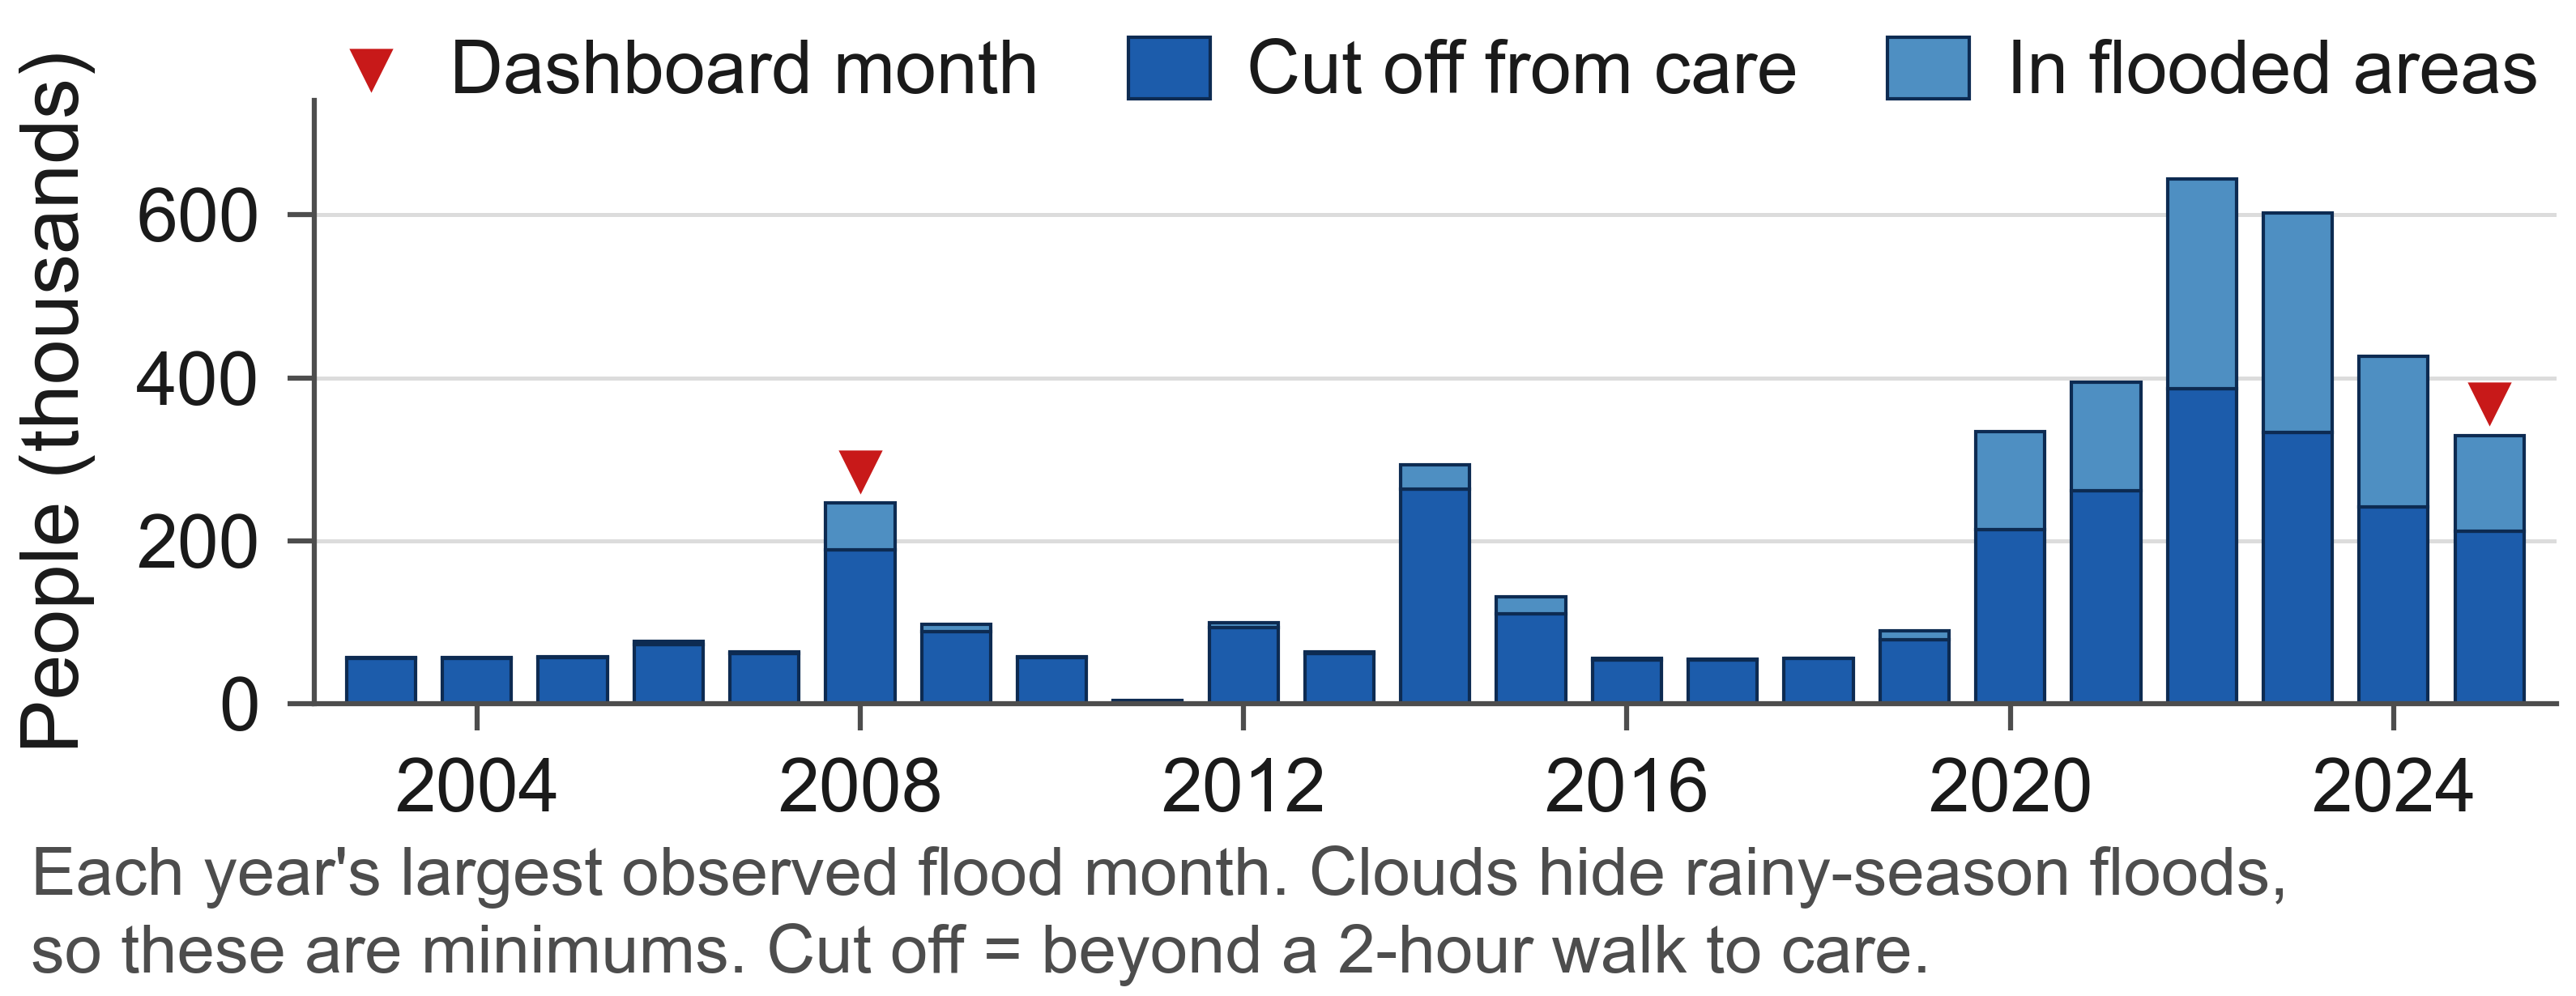

**protection_curve**

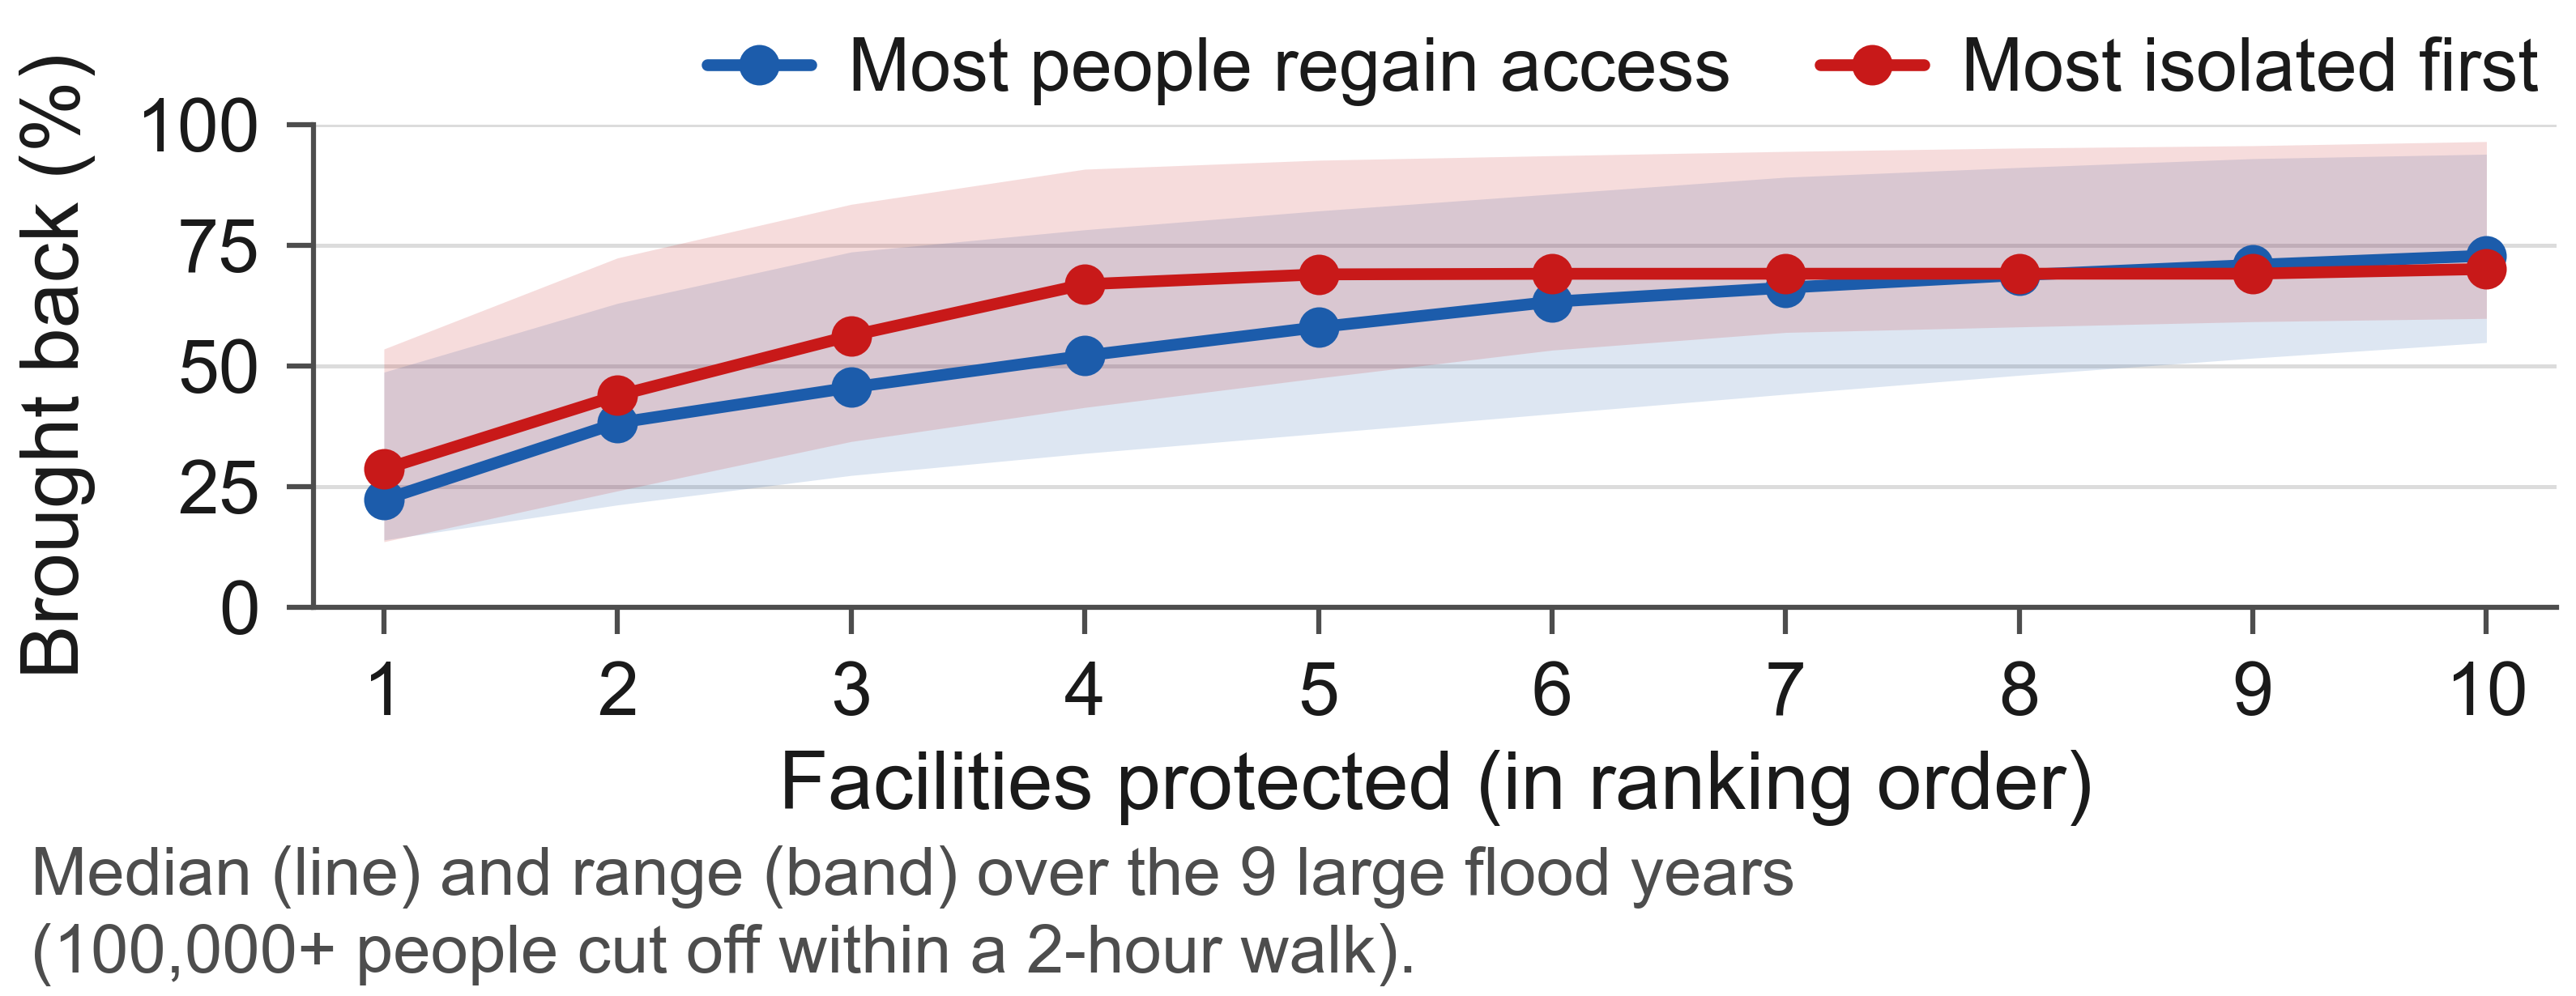

In [7]:
run_step("data_preparation.poster_figures")
for name in ["peak_access_loss", "protection_curve"]:
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(ROOT / "figures" / "poster" / f"{name}.png"), width=800))

## 8. Results
The numbers quoted in the report, read back from the output files.

### Baseline access (no flooding)

In [8]:
import numpy as np
from data_preparation.loading import load_baseline, load_static
from data_preparation.scenarios import scenario_flood

pop = load_static(cfg)["population"].astype("float64")
minutes = load_baseline("walking", cfg)[0]
no_flood_data = scenario_flood(SCENARIOS[0], cfg)[1]          # north of 10N
areas = {"whole country": np.ones_like(pop, bool), "south of 10N (with flood data)": ~no_flood_data}
rows = [{"area": name, "population": round(pop[mask].sum()),
         **{f"% within {m} min walk": round(100 * pop[mask & (minutes <= m)].sum() / pop[mask].sum(), 1) for m in (30, 60, 120)}}
        for name, mask in areas.items()]
display(pd.DataFrame(rows))

,area,population,% within 30 min walk,% within 60 min walk,% within 120 min walk
0,whole country,10560834,44.4,66.3,86.3
1,south of 10N (with flood data),10144240,44.4,66.6,86.7


### The four dashboard scenarios (walking, and motorised cut off)

In [9]:
rows = []
for s in SCENARIOS:
    access = json.load(open(ROOT / f"data/processed/access_loss/access_loss_{s}.json", encoding="utf-8"))
    ranks = json.load(open(ROOT / f"data/processed/priorities/priorities_{s}.json", encoding="utf-8"))["rankings"]
    walk, motor = access["modes"]["walking"], access["modes"].get("motorised", {})
    rows.append({"scenario": s, "facilities closed": access["facilities_closed"],
                 "in flooded cells": access["living_in_flooded_cells"], "cut off 2 h (walking)": walk["cut_off_120"],
                 "cut off 2 h (motorised)": motor.get("cut_off_120"), "no facility reachable": walk["no_facility_reachable"],
                 "Top 5 most saved brings back": ranks["most_saved"]["brought_back_by_top_n"],
                 "Top 5 worst-off brings back (of 4 h loss)": f"{ranks['worst_off']['brought_back_by_top_n']} of {ranks['worst_off']['people_losing_access']}"})
display(pd.DataFrame(rows))

,scenario,facilities closed,in flooded cells,cut off 2 h (walking),cut off 2 h (motorised),no facility reachable,Top 5 most saved brings back,Top 5 worst-off brings back (of 4 h loss)
0,2008-11,43,57691,188470,10368,6440,105258,12966 of 18795
1,2020-11,78,103845,279079,32648,1447,149121,89244 of 114579
2,2025-10,24,22090,86341,5778,1095,66627,16249 of 18526
3,2025-01,45,117750,211304,60000,16435,126754,42210 of 79086


### Access loss in the largest flood month of every year (Figure: `peak_access_loss`)

In [10]:
loss = pd.read_csv(EVAL / "peak_access_loss.csv")
display(loss)
print(f"cut off: {loss['cut_off'].min():,} to {loss['cut_off'].max():,} people; "
      f"median facilities closed {loss['sites_closed'].median():.0f}; "
      f"large flood years (>= {cfg['evaluation']['large_flood_cut_off']:,} cut off): {(loss['cut_off'] >= cfg['evaluation']['large_flood_cut_off']).sum()}")

,year,month,flooded_km2,cut_off,living_in_flooded_cells,no_facility_reachable,sites_closed,dashboard_scenario
0,2003,2003-01,605.0,56189,830,0,4,False
1,2004,2004-01,292.0,56104,233,0,4,False
2,2005,2005-12,707.0,56788,1018,2,9,False
3,2006,2006-12,1630.0,72675,3493,104,14,False
4,2007,2007-01,1852.0,61557,2322,90,10,False
5,2008,2008-11,1775.0,188470,57691,6440,42,True
6,2009,2009-01,2294.0,88900,8206,12,17,False
7,2010,2010-01,723.0,56920,526,6,4,False
8,2011,2011-01,807.0,2676,1796,13,4,False
9,2012,2012-12,1307.0,93525,5578,440,16,False


cut off: 2,676 to 386,807 people; median facilities closed 14; large flood years (>= 100,000 cut off): 9


### Protection ranking, simple rules, trade-off and pre-positioning: the large flood years
Medians over the large flood years (`large_years_summary.csv`): share brought back by the Top 5, greedy against the two simple rules (Table 3 of the report), what each Top 5 brings back on the other ranking's goal, the overlap of the two Top 5 lists and how concentrated the extra demand is.

In [11]:
display(pd.read_csv(EVAL / "large_years_summary.csv"))
summary = json.load(open(EVAL / "evaluation.json", encoding="utf-8"))
print("facilities ever in a Top 5:", summary["facilities_ever_in_a_top_n"])
display(pd.read_csv(EVAL / "top_frequency.csv").head(10))

,measure,value
0,share_brought_back_by_top_n.most_saved.median,0.580
1,share_brought_back_by_top_n.most_saved.min,0.360
2,share_brought_back_by_top_n.most_saved.max,0.821
3,share_brought_back_by_top_n.worst_off.median,0.690
4,share_brought_back_by_top_n.worst_off.min,0.475
5,share_brought_back_by_top_n.worst_off.max,0.926
6,naive_comparison.most_saved.median_share_broug...,0.580
7,naive_comparison.most_saved.median_share_broug...,0.460
8,naive_comparison.most_saved.median_share_broug...,0.398
9,naive_comparison.most_saved.median_greedy_time...,1.210


facilities ever in a Top 5: 56


,site_id,years_top_most_saved,years_top_worst_off,years_top_either,adm2_name,adm1_name,rep_facility_type,n_facilities
0,891,22,0,22,Awerial,Lakes,Primary Health Care Unit,2
1,889,7,18,18,Awerial,Lakes,Primary Health Care Centre,1
2,559,2,8,8,Ayod,Jonglei,Primary Health Care Unit,1
3,717,4,7,7,Yirol East,Lakes,Primary Health Care Centre,1
4,867,6,7,7,Awerial,Lakes,Primary Health Care Unit,1
5,601,4,6,6,Ayod,Jonglei,Primary Health Care Unit,1
6,114,5,0,5,Fangak,Jonglei,Primary Health Care Centre,1
7,358,5,4,5,Ulang,Upper Nile,Primary Health Care Centre,1
8,374,4,3,5,Ulang,Upper Nile,Primary Health Care Unit,1
9,149,3,4,4,Fangak,Jonglei,Primary Health Care Centre,1


### Plausibility: our closed facilities against the WHO reports (Table 4 of the report)

In [12]:
check = pd.read_csv(EVAL / "external_check.csv")
display(check[["report", "window", "closed_report_month", "closed_any_month", "reported_text"]])
monthly = pd.read_csv(EVAL / "external_check_monthly.csv")
display(monthly.pivot(index="month", columns="report_month", values="flooded_km2").fillna(""))

,report,window,closed_report_month,closed_any_month,reported_text
0,WHO situation report #17,2021-04 to 2021-10,67,70,"over 60 health facilities cut off, submerged o..."
1,WHO AFRO news release,2024-04 to 2024-10,36,42,"58 health facilities submerged, nearly 90 othe..."
2,WHO Public Health Situation Analysis,2025-06 to 2025-10,24,26,flooding since June 2025; 143 health facilitie...


report_month,2021-10,2024-10,2025-10
month,,,
2021-04,569.0,,
2021-05,604.0,,
2021-06,456.0,,
2021-07,382.0,,
2021-08,1078.0,,
2021-09,809.0,,
2021-10,2582.0,,
2021-11,3380.0,,
2021-12,3792.0,,


## 9. Tests
58 unit tests on small synthetic grids: the travel-time engine against SciPy's Dijkstra, no step ever makes travel faster when cells are blocked, reopening one facility gives exactly the same result as a full rerun, and population is never lost or counted twice.

In [13]:
if RUN_TESTS:
    result = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout[-1500:])

..........................................................               [100%]
58 passed in 2.29s



## 10. Dashboard
The dashboard only reads the precomputed outputs above. Start it from a terminal in the repository root:

```
$env:PYTHONPATH = "."; streamlit run dashboard.py     # Windows PowerShell
PYTHONPATH=. streamlit run dashboard.py               # macOS / Linux
```

All outputs are a screening tool for humanitarian staff to verify locally, not instructions to the population (see the README, *Legal and ethical considerations*).